# FinanceWise — Student Spending Behaviour Classification

**Purpose:** Develop and compare Logistic Regression and other supervised classifiers for *constructed* Low, Moderate, and High spending categories. The original dataset contains **1,000 synthetic, non-Kenyan student records**. The improved model uses currency-independent financial ratios to support KES input in FinanceWise.

**Interpretation limits:** The labels are generated from the spending-to-income ratio; they are not independently observed outcomes or established Kenyan financial-health standards. The model's accuracy measures agreement with constructed labels, not real-world Kenyan validity. Tuition is excluded because its reporting period is unclear; periods for other expenses are also not fully documented. 

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
CLASS_ORDER = ["Low", "Moderate", "High"]
print("Libraries imported successfully.")

Libraries imported successfully.


### Output interpretation

- The required libraries loaded successfully.
- We can now clean data, create graphs, train models and measure performance.

## 2. Load and inspect the original dataset

Place the original CSV beside this notebook or in `dataset/raw/`. If neither exists, edit `DATA_PATH` to point to your original CSV. An optional Windows path is included; change it if your CSV is stored elsewhere.

In [2]:
candidates = [
    Path("student_spending (1).csv"),
    Path("dataset/raw/student_spending (1).csv"),
    Path(r"C:\xammp2\htdocs\Final_Project\FinanceTrackingLearning_Project\personal_finance_system\machine_learning\dataset\raw\student_spending (1).csv"),
]
DATA_PATH = next((path for path in candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Original dataset not found. Set DATA_PATH to your original student_spending (1).csv file.")

df = pd.read_csv(DATA_PATH)
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
print("Dataset:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())
df.info()

Dataset: C:\xammp2\htdocs\Final_Project\FinanceTrackingLearning_Project\personal_finance_system\machine_learning\dataset\raw\student_spending (1).csv
Shape: (1000, 17)


,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,188,41,78,134,127,72,Credit/Debit Card
1,24,Female,Junior,Economics,1006,875,4908,557,365,85,252,74,92,226,129,68,Credit/Debit Card
2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,99,130,23,239,112,133,Cash
3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,223,99,30,163,105,55,Mobile Payment App
4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,194,48,71,88,71,104,Credit/Debit Card


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   age                       1000 non-null   int64
 1   gender                    1000 non-null   str  
 2   year_in_school            1000 non-null   str  
 3   major                     1000 non-null   str  
 4   monthly_income            1000 non-null   int64
 5   financial_aid             1000 non-null   int64
 6   tuition                   1000 non-null   int64
 7   housing                   1000 non-null   int64
 8   food                      1000 non-null   int64
 9   transportation            1000 non-null   int64
 10  books_supplies            1000 non-null   int64
 11  entertainment             1000 non-null   int64
 12  personal_care             1000 non-null   int64
 13  technology                1000 non-null   int64
 14  health_wellness           1000 non-null   int64
 15 

### Output interpretation

- The dataset shape shows how many student records and columns were loaded.
- The first five rows provide examples of student information.
- The column information shows data types and whether any values are missing.

## 3. Data quality checks and exploratory data analysis

In [3]:
print("Missing values per column:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Numeric summary:")
display(df.describe().round(2))

expense_columns = [
    "housing", "food", "transportation", "books_supplies",
    "entertainment", "personal_care", "technology",
    "health_wellness", "miscellaneous"
]
original_features = ["monthly_income"] + expense_columns
required_columns = original_features + ["tuition", "financial_aid"]
missing = sorted(set(required_columns) - set(df.columns))
if missing:
    raise ValueError(f"Required dataset columns are missing: {missing}")
if df[original_features].isna().any().any():
    raise ValueError("Financial predictors contain missing values. Review before modeling.")
if (df["monthly_income"] <= 0).any():
    raise ValueError("Income must be positive to calculate spending ratios.")
if (df[expense_columns] < 0).any().any():
    raise ValueError("Expense values must not be negative.")

Missing values per column:
 age                         0
gender                      0
year_in_school              0
major                       0
monthly_income              0
financial_aid               0
tuition                     0
housing                     0
food                        0
transportation              0
books_supplies              0
entertainment               0
personal_care               0
technology                  0
health_wellness             0
miscellaneous               0
preferred_payment_method    0
dtype: int64
Duplicate rows: 0
Numeric summary:


,age,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.0,1000.00,1000.00,1000.00
mean,21.68,1020.65,504.77,4520.40,696.01,252.64,124.64,174.76,84.81,60.7,178.30,114.31,108.91
std,2.32,293.84,287.09,860.66,171.22,86.95,43.56,72.40,37.97,22.9,71.74,49.59,52.41
min,18.00,501.00,0.00,3003.00,401.00,100.00,50.00,50.00,20.00,20.0,50.00,30.00,20.00
25%,20.00,770.75,261.00,3779.75,538.75,175.00,88.00,112.00,54.00,41.0,114.00,73.00,63.75
50%,22.00,1021.00,513.00,4547.50,704.50,255.00,123.00,175.00,86.00,62.0,178.00,115.00,110.00
75%,24.00,1288.25,751.50,5285.00,837.25,330.00,162.25,238.00,116.00,80.0,241.00,158.00,153.00
max,25.00,1500.00,1000.00,6000.00,1000.00,400.00,200.00,300.00,150.00,100.0,300.00,200.00,200.00


### Output interpretation

- A value of **0** for missing data means that column has no empty entries.
- **0 duplicate rows** means no records are repeated exactly.
- The summary shows the average, smallest, largest and spread of numeric values.
- For this dataset, there are **1,000 records** and the average monthly income is **1,020.65** in the original units.

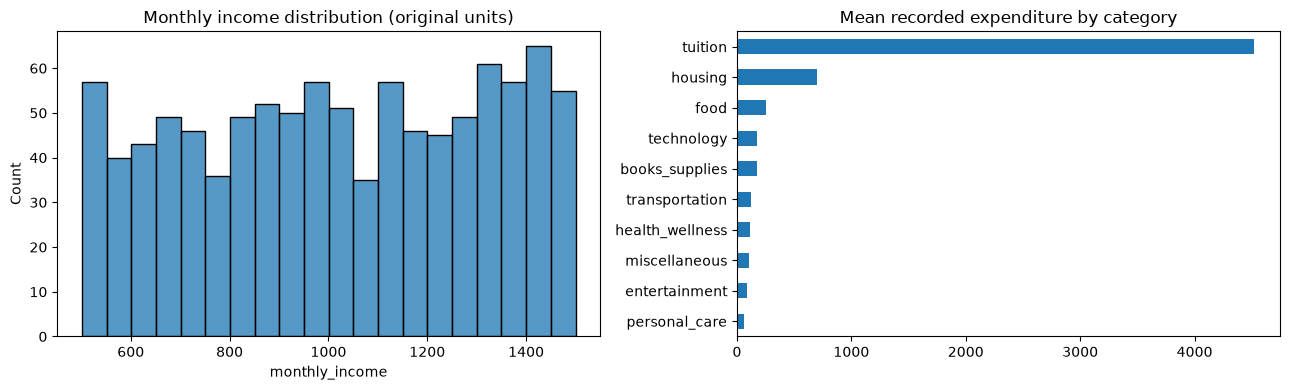

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["monthly_income"], bins=20, ax=axes[0])
axes[0].set_title("Monthly income distribution (original units)")
df[expense_columns + ["tuition"]].mean().sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Mean recorded expenditure by category")
plt.tight_layout()
plt.show()

### Output interpretation

- The income graph shows which income amounts are more common among students.
- The bar chart compares the average amounts recorded for each expense category.
- Tuition is shown separately because its reporting period may differ from monthly expenses.

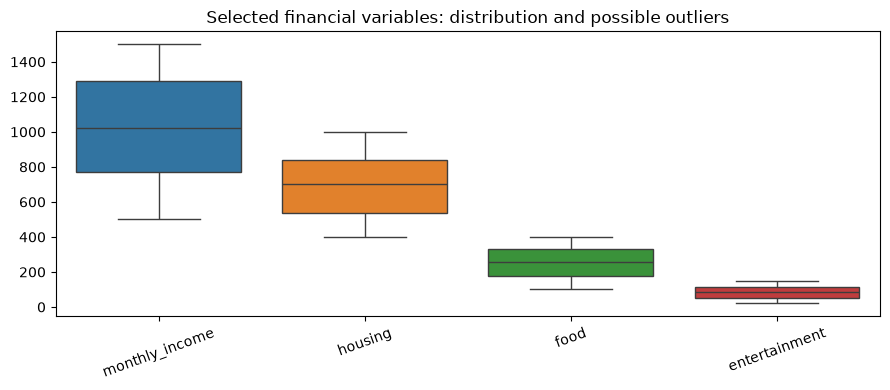

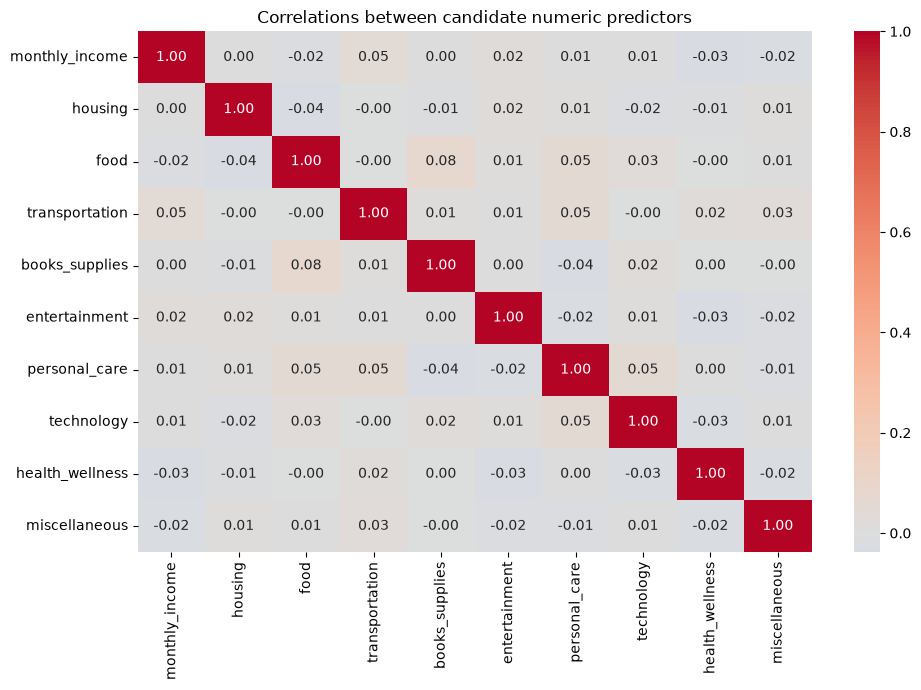

In [5]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=df[["monthly_income", "housing", "food", "entertainment"]])
plt.title("Selected financial variables: distribution and possible outliers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df[original_features].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlations between candidate numeric predictors")
plt.tight_layout()
plt.show()

### Output interpretation

- The boxplot shows the middle range and spread of income and selected expenses; individual points may indicate unusual values.
- The correlation heatmap shows how strongly two numeric variables move together.
- Values near **+1** indicate a positive relationship, near **−1** a negative relationship, and near **0** little linear relationship.
- Correlation does not prove that one variable causes another.

## 4. Feature engineering: total expenses, spending ratio, and proportions

Exclude `tuition` because the source does not clearly establish its time period. Ratios are **relative synthetic indicators**. Proportions describe how expenses are allocated, while the spending ratio compares included expenses with recorded income.

In [6]:
df_model = df.copy()
df_model["non_tuition_expenses"] = df_model[expense_columns].sum(axis=1)
if (df_model["non_tuition_expenses"] <= 0).any():
    raise ValueError("Total non-tuition expenses must be positive for proportion features.")
df_model["spending_ratio"] = df_model["non_tuition_expenses"] / df_model["monthly_income"]
proportion_features = [f"{name}_proportion" for name in expense_columns]
for name in expense_columns:
    df_model[f"{name}_proportion"] = df_model[name] / df_model["non_tuition_expenses"]

print(df_model["spending_ratio"].describe().round(3))
display(df_model[["spending_ratio"] + proportion_features].head())
assert np.allclose(df_model[proportion_features].sum(axis=1), 1.0)

count    1000.000
mean        1.937
std         0.702
min         0.797
25%         1.399
50%         1.730
75%         2.341
max         4.365
Name: spending_ratio, dtype: float64


,spending_ratio,housing_proportion,food_proportion,transportation_proportion,books_supplies_proportion,entertainment_proportion,personal_care_proportion,technology_proportion,health_wellness_proportion,miscellaneous_proportion
0,1.845511,0.401018,0.167421,0.069570,0.106335,0.023190,0.044118,0.075792,0.071833,0.040724
1,1.836978,0.301407,0.197511,0.045996,0.136364,0.040043,0.049784,0.122294,0.069805,0.036797
2,2.396458,0.378624,0.125071,0.077885,0.056282,0.073906,0.013076,0.135873,0.063673,0.075611
3,2.803890,0.376879,0.167052,0.065896,0.128902,0.057225,0.017341,0.094220,0.060694,0.031792
4,2.396296,0.425039,0.191654,0.086553,0.099948,0.024730,0.036579,0.045337,0.036579,0.053581


### Output interpretation

- The spending ratio compares total non-tuition expenses with monthly income.
- For example, a ratio of **1.5** means reported expenses are 1.5 times income; the expense periods must be comparable for this to represent a monthly budget position.
- Each expense proportion shows the share of total included spending used for that category.
- The nine proportions add up to **1 (100%)** for each student.

## 5. Split first; construct labels from training-only thresholds

Use an 80:20 holdout. The 33⅓ and 66⅔ percentile cutoffs are learned only from the training partition. This prevents the test-set ratio distribution from influencing the label thresholds. Because the labels are constructed from a ratio, they remain a **rule-derived proxy target**.

In [7]:
train_idx, test_idx = train_test_split(df_model.index, test_size=0.20, random_state=RANDOM_STATE)
train_ratio = df_model.loc[train_idx, "spending_ratio"]
test_ratio = df_model.loc[test_idx, "spending_ratio"]
low_threshold = float(train_ratio.quantile(1/3))
high_threshold = float(train_ratio.quantile(2/3))

def assign_category(ratio):
    if ratio <= low_threshold:
        return "Low"
    if ratio <= high_threshold:
        return "Moderate"
    return "High"

y_train = train_ratio.map(assign_category)
y_test = test_ratio.map(assign_category)
print(f"Low threshold: {low_threshold:.6f}")
print(f"High threshold: {high_threshold:.6f}")
print("Training records:", len(train_idx), "Testing records:", len(test_idx))
print("Training labels:\n", y_train.value_counts())
print("Testing labels:\n", y_test.value_counts())

Low threshold: 1.496436
High threshold: 2.052398
Training records: 800 Testing records: 200
Training labels:
 spending_ratio
High        267
Low         267
Moderate    266
Name: count, dtype: int64
Testing labels:
 spending_ratio
High        73
Low         64
Moderate    63
Name: count, dtype: int64


### Output interpretation

- **800 records** are used for training and **200** for testing.
- The low and high cutoffs are calculated from training records only to avoid using test information.
- Students are assigned **Low, Moderate or High** labels based on their spending ratios.
- These are constructed labels, not independently measured financial behaviour.

## 6. Baseline experiment: original monetary features

All four algorithms are trained and evaluated here, so no separate algorithm-comparison notebook is required. Logistic Regression, KNN and GaussianNB use scaling fitted on training data only; the Decision Tree does not require scaling. **These scores should not be interpreted as independent financial-behaviour validation.**

In [8]:
X_train_original = df_model.loc[train_idx, original_features].copy()
X_test_original = df_model.loc[test_idx, original_features].copy()

baseline_models = {
    "Logistic Regression (raw amounts)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree (raw amounts)": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "KNN (raw amounts)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Gaussian NB (raw amounts)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ])
}
baseline_results = []
for name, estimator in baseline_models.items():
    estimator.fit(X_train_original, y_train)
    pred = estimator.predict(X_test_original)
    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro")
    })
results_baseline = pd.DataFrame(baseline_results).sort_values("Macro F1", ascending=False)
display(results_baseline.round(4))

,Model,Accuracy,Macro F1
0,Logistic Regression (raw amounts),0.975,0.9751
3,Gaussian NB (raw amounts),0.800,0.7993
1,Decision Tree (raw amounts),0.790,0.7870
2,KNN (raw amounts),0.710,0.7066


### Output interpretation

- The table compares four machine learning algorithms using the original income and expense amounts.
- **Accuracy** is the share of test predictions that are correct; **Macro F1** balances performance across the three categories.
- Check the **Logistic Regression** row for its actual accuracy in this run; do not assume a previous result.
- Because the categories are calculated from the financial amounts, high accuracy mainly shows that the model learned the labeling rule.

## 7. Experiment: expense proportions only

These nine features are currency-independent but **omit the spending-to-income ratio that defines the labels**. This experiment tests whether expense allocation alone carries useful signal; prior runs found approximately 28.5% accuracy, but outputs will be recomputed.

In [9]:
X_train_proportions = df_model.loc[train_idx, proportion_features].copy()
X_test_proportions = df_model.loc[test_idx, proportion_features].copy()
proportion_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
proportion_pipeline.fit(X_train_proportions, y_train)
proportion_pred = proportion_pipeline.predict(X_test_proportions)
print("Proportions-only accuracy:", round(accuracy_score(y_test, proportion_pred), 4))
print("Proportions-only macro F1:", round(f1_score(y_test, proportion_pred, average="macro"), 4))
print(classification_report(y_test, proportion_pred, labels=CLASS_ORDER))
display(df_model.loc[train_idx].assign(spending_behaviour=y_train).groupby("spending_behaviour")[proportion_features].mean().round(3))

Proportions-only accuracy: 0.285
Proportions-only macro F1: 0.2799
              precision    recall  f1-score   support

         Low       0.28      0.30      0.29        64
    Moderate       0.21      0.19      0.20        63
        High       0.35      0.36      0.35        73

    accuracy                           0.28       200
   macro avg       0.28      0.28      0.28       200
weighted avg       0.28      0.28      0.28       200



,housing_proportion,food_proportion,transportation_proportion,books_supplies_proportion,entertainment_proportion,personal_care_proportion,technology_proportion,health_wellness_proportion,miscellaneous_proportion
spending_behaviour,,,,,,,,,
High,0.397,0.142,0.067,0.096,0.045,0.034,0.098,0.062,0.058
Low,0.381,0.138,0.073,0.096,0.048,0.036,0.099,0.066,0.063
Moderate,0.381,0.144,0.070,0.097,0.049,0.034,0.101,0.064,0.060


### Output interpretation

- This experiment uses only the percentages spent in each category, without comparing expenses to income.
- Read the printed accuracy and Macro F1 to see how well the proportions-only model performed in this run.
- The group-average table shows whether Low, Moderate and High groups have different spending proportions.

## 8. Improved currency-independent ML features

Combine the **spending ratio** and nine expenditure proportions. These inputs are unchanged by multiplying *all* monetary inputs by the same exchange rate, making them suitable for KES-denominated UI input. **Caution:** The ratio also directly defines the synthetic target, so strong classification scores mainly show recovery of the constructed rule.

In [10]:
improved_features = ["spending_ratio"] + proportion_features
X_train = df_model.loc[train_idx, improved_features].copy()
X_test = df_model.loc[test_idx, improved_features].copy()

improved_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
improved_pipeline.fit(X_train, y_train)
improved_pred = improved_pipeline.predict(X_test)
print("Training shape:", X_train.shape, "Testing shape:", X_test.shape)
print("Accuracy:", round(accuracy_score(y_test, improved_pred), 4))
print("Macro F1:", round(f1_score(y_test, improved_pred, average="macro"), 4))
print(classification_report(y_test, improved_pred, labels=CLASS_ORDER))

Training shape: (800, 10) Testing shape: (200, 10)
Accuracy: 0.965
Macro F1: 0.9646
              precision    recall  f1-score   support

         Low       0.96      1.00      0.98        64
    Moderate       0.94      0.95      0.94        63
        High       1.00      0.95      0.97        73

    accuracy                           0.96       200
   macro avg       0.96      0.97      0.96       200
weighted avg       0.97      0.96      0.97       200



### Output interpretation

- The improved model uses **10 features**: spending ratio plus nine expense proportions.
- The training and testing shapes show the number of records and input features.
- Accuracy and Macro F1 show how well the model reproduces the constructed Low, Moderate and High categories.
- The classification report breaks results down by category: precision, recall, F1-score and number of test examples.

## 9. Tune the improved model using training data only

Use five-fold stratified cross-validation, macro F1 scoring, and compatible `lbfgs` solver. **Methodological limitation:** The target cutoffs were computed from the full 800-row training partition before cross-validation. Fold-specific cutoff recomputation would be stricter, but the current results should be described as exploratory.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs"],
    "classifier__class_weight": [None, "balanced"]
}
grid_search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best CV macro F1:", round(grid_search.best_score_, 4))
cv_table = pd.DataFrame(grid_search.cv_results_)
display(cv_table[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(5))

Best parameters: {'classifier__C': 100, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}
Best CV macro F1: 0.9888


,params,mean_test_score,std_test_score,rank_test_score
9,"{'classifier__C': 100, 'classifier__class_weig...",0.988829,0.009849,1
8,"{'classifier__C': 100, 'classifier__class_weig...",0.988829,0.009849,1
6,"{'classifier__C': 10, 'classifier__class_weigh...",0.987593,0.010324,3
7,"{'classifier__C': 10, 'classifier__class_weigh...",0.987593,0.010324,3
4,"{'classifier__C': 1, 'classifier__class_weight...",0.975067,0.013069,5


### Output interpretation

- GridSearchCV tries different Logistic Regression settings using only the training data.
- **Five-fold cross-validation** checks the settings across five different training/validation partitions.
- The best parameters and highest average Macro F1 indicate which settings performed best during tuning.
- The top-five table shows other strong settings and how consistent their scores were.

## 10. Holdout evaluation and model comparison

Inspect the 200-record test partition **after** training and tuning. The holdout results are exploratory because the same synthetic dataset has been used during model development. Do not select more hyperparameters based on this output.

Tuned model accuracy: 1.0
Tuned model macro F1: 1.0
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00        64
    Moderate       1.00      1.00      1.00        63
        High       1.00      1.00      1.00        73

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



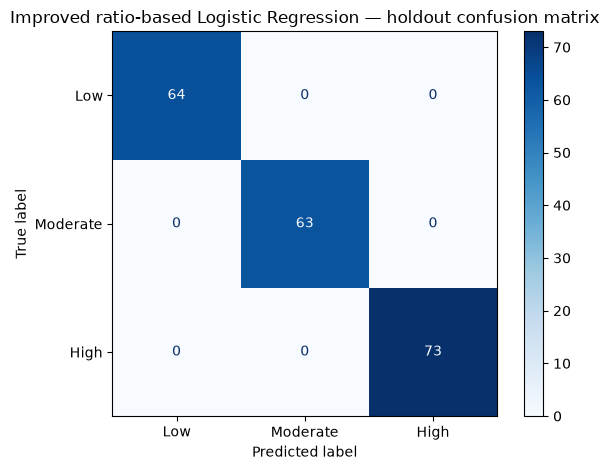

,Model,Accuracy,Macro F1
6,Ratio + proportions (tuned),1.000,1.0000
0,Logistic Regression (raw amounts),0.975,0.9751
5,Ratio + proportions (untuned),0.965,0.9646
1,Gaussian NB (raw amounts),0.800,0.7993
2,Decision Tree (raw amounts),0.790,0.7870
3,KNN (raw amounts),0.710,0.7066
4,Proportions only,0.285,0.2799


In [12]:
tuned_pred = best_model.predict(X_test)
print("Tuned model accuracy:", round(accuracy_score(y_test, tuned_pred), 4))
print("Tuned model macro F1:", round(f1_score(y_test, tuned_pred, average="macro"), 4))
print(classification_report(y_test, tuned_pred, labels=CLASS_ORDER))
ConfusionMatrixDisplay.from_predictions(
    y_test, tuned_pred, labels=CLASS_ORDER, cmap="Blues", values_format="d"
)
plt.title("Improved ratio-based Logistic Regression — holdout confusion matrix")
plt.tight_layout()
plt.show()

comparison = pd.concat([
    results_baseline[["Model", "Accuracy", "Macro F1"]],
    pd.DataFrame([
        {"Model": "Proportions only", "Accuracy": accuracy_score(y_test, proportion_pred), "Macro F1": f1_score(y_test, proportion_pred, average="macro")},
        {"Model": "Ratio + proportions (untuned)", "Accuracy": accuracy_score(y_test, improved_pred), "Macro F1": f1_score(y_test, improved_pred, average="macro")},
        {"Model": "Ratio + proportions (tuned)", "Accuracy": accuracy_score(y_test, tuned_pred), "Macro F1": f1_score(y_test, tuned_pred, average="macro")}
    ])
], ignore_index=True)
display(comparison.sort_values("Macro F1", ascending=False).round(4))

### Output interpretation

- The tuned accuracy and Macro F1 measure performance on the held-out test records.
- In the classification report, **precision** is how reliable predictions of each class are, **recall** is how many actual examples of that class are found, and **F1** balances both.
- The confusion matrix shows correct predictions on the diagonal and mistakes outside it.
- The comparison table shows whether adding the spending ratio and tuning improved results.
- High scores still do **not** establish accuracy on real Kenyan student spending behaviour because the labels were created from the spending ratio.

## 11. Verify currency invariance (USD → illustrative KES)

**This is a mathematical invariance test, not Kenyan population validation.** Converting every monetary amount by the same factor leaves ratios and proportions unchanged. The rate `130` below is illustrative only; it is not a live exchange rate.

In [13]:
illustrative_usd_to_kes = 130.0
sample_original = df_model.loc[test_idx[:5], original_features].copy()
sample_kes = sample_original * illustrative_usd_to_kes

def make_currency_independent_features(financial_rows):
    """Create the ten model inputs from same-period income and expense amounts."""
    financial_rows = financial_rows.copy()
    if (financial_rows["monthly_income"] <= 0).any():
        raise ValueError("Income must be greater than zero.")
    if (financial_rows[expense_columns] < 0).any().any():
        raise ValueError("Expenses cannot be negative.")
    total = financial_rows[expense_columns].sum(axis=1)
    if (total <= 0).any():
        raise ValueError("Total included expenses must be greater than zero.")
    features = pd.DataFrame(index=financial_rows.index)
    features["spending_ratio"] = total / financial_rows["monthly_income"]
    for col in expense_columns:
        features[f"{col}_proportion"] = financial_rows[col] / total
    return features[improved_features]

features_usd = make_currency_independent_features(sample_original)
features_kes = make_currency_independent_features(sample_kes)
assert np.allclose(features_usd.to_numpy(), features_kes.to_numpy())
assert np.array_equal(best_model.predict(features_usd), best_model.predict(features_kes))
print("PASS: predictions are identical after a uniform currency conversion.")
print("Example predictions:", best_model.predict(features_kes))

PASS: predictions are identical after a uniform currency conversion.
Example predictions: ['Moderate' 'Moderate' 'Moderate' 'High' 'Low']


### Output interpretation

- **PASS** means the model produced the same predictions before and after multiplying all financial amounts by the same exchange-rate factor.
- This works because the model uses ratios and proportions rather than currency amounts.
- The test demonstrates currency invariance; it does **not** validate the model on real Kenyan students.

## 12. Save the final improved model and configuration

Save the **new** pipeline and matching feature metadata, under its own clearly named filenames. The saved configuration includes the training-derived label thresholds for reproducibility. Only load joblib files from trusted sources.

In [14]:
output_dir = Path("saved_models")
output_dir.mkdir(parents=True, exist_ok=True)
model_path = output_dir / "spending_classifier_ratio_based.pkl"
config_path = output_dir / "spending_classifier_ratio_config.pkl"
joblib.dump(best_model, model_path)
config = {
    "feature_columns": improved_features,
    "expense_columns": expense_columns,
    "low_threshold": low_threshold,
    "high_threshold": high_threshold,
    "class_labels": CLASS_ORDER,
    "input_currency": "currency-independent ratios (KES accepted)",
    "label_origin": "training-set spending-ratio tertiles; synthetic proxy labels",
    "training_dataset": "original synthetic Student Spending Habits Dataset",
    "limitation": "Not validated on real Kenyan student records"
}
joblib.dump(config, config_path)
print("Saved model:", model_path.resolve())
print("Saved configuration:", config_path.resolve())

Saved model: C:\xammp2\htdocs\Final_Project\FinanceTrackingLearning_Project\personal_finance_system\machine_learning\notebooks\saved_models\spending_classifier_ratio_based.pkl
Saved configuration: C:\xammp2\htdocs\Final_Project\FinanceTrackingLearning_Project\personal_finance_system\machine_learning\notebooks\saved_models\spending_classifier_ratio_config.pkl


### Output interpretation

- The model file stores the trained Logistic Regression pipeline for use in Django.
- The configuration file stores the required feature names, category order and label thresholds.
- Both files are needed to prepare inputs consistently when FinanceWise makes predictions.

## 13. Reload and smoke-test the saved model

The Django application should load the saved pipeline once, calculate the same ten features in the same order, and then call `.predict()`. The notebook intentionally does not change your Django files.

In [15]:
reloaded_model = joblib.load(model_path)
reloaded_config = joblib.load(config_path)
assert reloaded_config["feature_columns"] == improved_features
assert np.array_equal(reloaded_model.predict(X_test.head(5)), best_model.predict(X_test.head(5)))
print("Reload test passed.")
print("Required input features:", reloaded_config["feature_columns"])
print("Five predictions:", reloaded_model.predict(X_test.head(5)))

Reload test passed.
Required input features: ['spending_ratio', 'housing_proportion', 'food_proportion', 'transportation_proportion', 'books_supplies_proportion', 'entertainment_proportion', 'personal_care_proportion', 'technology_proportion', 'health_wellness_proportion', 'miscellaneous_proportion']
Five predictions: ['Moderate' 'Moderate' 'Moderate' 'High' 'Low']


### Output interpretation

- **Reload test passed** means the saved model can be opened again and still makes the same predictions.
- The feature list shows the exact inputs Django must supply in the correct order.
- The five predictions are examples of the model classifying test records as Low, Moderate or High.

## 14. FinanceWise integration notes and methodological conclusions

**Django feature preparation:** Aggregate user transactions into a *consistent time window*; use positive monthly income and nonnegative expense amounts; map Django categories to the nine training categories; compute the spending ratio and expense proportions exactly as in `make_currency_independent_features()`; pass a DataFrame with the saved `feature_columns` order. For zero income or zero expenses, handle the case explicitly in the application instead of dividing by zero or silently filling values.

**Kenyan context:** Display monetary values in KES and support M-Pesa and locally relevant categories in the interface. Currency-invariant features avoid an arbitrary USD↔KES conversion at prediction time, **but do not make synthetic non-Kenyan data representative of Kenyan youth**. Test with realistic Kenyan scenarios and seek appropriately sourced local validation data when possible.

**Key findings:** (1) Expense proportions alone were weak predictors of the constructed categories. (2) Adding spending ratio restores the information used to define those categories. (3) A strong score on this task is not proof of independent predictive validity; it largely measures reconstruction of the target rule. (4) A transparent direct-ratio calculation is a useful benchmark, even though the FYP prototype retains Logistic Regression as its experimental ML classification component.

**For Chapter 4:** Document the 80:20 split, training-only percentile thresholds, class distribution, model comparisons, five-fold tuning, holdout metrics, confusion matrix, saved pipeline, currency-invariance test, and limitations. Avoid claiming that tuition and other expense periods are verified or that the thresholds measure financial health in Kenya.

**Potential future improvement:** Obtain real, independently assessed labels or a different meaningful target (e.g., verified budget adherence) to evaluate genuine predictive usefulness rather than predicting labels calculated from the inputs.